# 02 — Wants baseline (EDA + TF-IDF baseline)

INTENT-2026-11-11-03: first ML pass over structured wants extracted from each AI agent's sessions.
EDA over intensity / cluster / agent, then a small sklearn baseline that predicts a want's cluster from its title.

Seed of the Muse-side role: *decide what to do from data* (wants -> intent -> order).

Data: `data/bronze/wants.jsonl` (12 rows: Grok 6 + Muse 6), `data/bronze/sessions.jsonl` (index 16).

In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("..")
rows = [json.loads(l) for l in (ROOT/"data/bronze/wants.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()]
df = pd.DataFrame(rows)
print("shape:", df.shape)
df.head()

shape: (12, 12)


              id  ...                                          source
0  W-20261111-01  ...       metaのmuseみたいなのってmanus以外にもあるのかなdots botとかか
1  W-20261111-02  ...             kaggleで何をｍｌすべきかな　今の私の状況　セッションから分析して
2  W-20261111-03  ...                          bqmlしたいです kaggleで再現します
3  W-20261111-04  ...  bonsai/kaggle-bqml-coreとして共通基盤だけ実装しよう template
4  W-20261111-05  ...                  セッションを整理して保存 / 過去のintentも救い出して

[5 rows x 12 columns]

## 1. EDA — counts

In [2]:
print("by cluster:")
print(df.groupby("cluster").size().sort_values(ascending=False))
print()
print("by agent (extracted_by):")
print(df.groupby("extracted_by").size())
print()
print("intensity: mean=%.3f min=%.2f max=%.2f" % (df.intensity.mean(), df.intensity.min(), df.intensity.max()))
print()
print("status:")
print(df.status.value_counts())

by cluster:
cluster
ml-data         5
meta-process    4
agents          2
business        1
dtype: int64

by agent (extracted_by):
extracted_by
Grok (xAI)    6
Muse          6
dtype: int64

intensity: mean=0.800 min=0.60 max=0.95

status:
status
active    6
stated    3
done      3
Name: count, dtype: int64


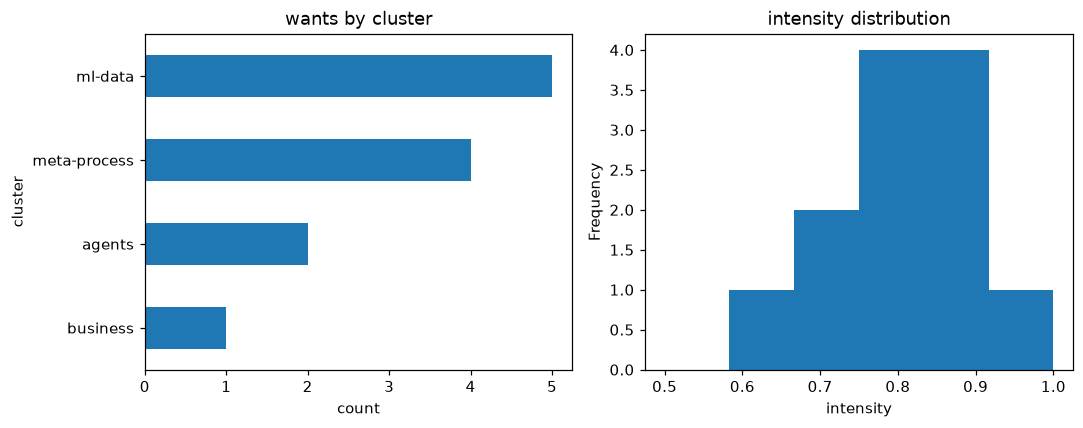

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))
df.groupby("cluster").size().sort_values().plot.barh(ax=axes[0], title="wants by cluster")
axes[0].set_xlabel("count")
df.intensity.plot.hist(ax=axes[1], bins=6, title="intensity distribution", range=(0.5,1.0))
axes[1].set_xlabel("intensity")
plt.tight_layout()
plt.show()

## 2. depends_on / enables graph

In [4]:
edges = []
for r in rows:
    for e in r.get("enables", []):
        edges.append((r["id"], e, "enables"))
    for d in r.get("depends_on", []):
        edges.append((r["id"], d, "depends_on"))
print("edges:", len(edges))
for e in edges:
    print(e)

edges: 14
('W-20261111-01', 'W-20261111-02', 'enables')
('W-20261111-01', 'W-20261111-05', 'enables')
('W-20261111-02', 'W-20261111-03', 'enables')
('W-20261111-03', 'W-past-kb009-full', 'enables')
('W-20261111-03', 'W-20261111-02', 'depends_on')
('W-20261111-04', 'W-20261111-06', 'enables')
('W-20261111-04', 'W-20261111-03', 'depends_on')
('W-20261111-05', 'W-20261111-06', 'enables')
('W-20261111-06', 'W-20261111-05', 'depends_on')
('W-20261111-M02', 'W-20261111-M06', 'enables')
('W-20261111-M03', 'W-20261111-M06', 'enables')
('W-20261111-M04', 'W-20261111-M06', 'enables')
('W-20261111-M06', 'W-20261111-M02', 'depends_on')
('W-20261111-M06', 'W-20261111-M04', 'depends_on')


## 3. Baseline — title -> cluster (TF-IDF + Logistic Regression, leave-one-out)

Only 12 rows, so evaluation is leave-one-out; numbers are not to be over-trusted.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

X = df["title"].astype(str).tolist()
y = df["cluster"].astype(str).tolist()
vec = TfidfVectorizer(analyzer="char", ngram_range=(2,4))
Xv = vec.fit_transform(X)
clf = LogisticRegression(max_iter=1000, C=1.0)
pred = cross_val_predict(clf, Xv, y, cv=LeaveOneOut())
acc = accuracy_score(y, pred)
print("LOO accuracy: %.3f (n=%d)" % (acc, len(y)))
print()
labels = sorted(set(y))
print("confusion matrix (rows=actual, cols=pred), labels=", labels)
print(confusion_matrix(y, pred, labels=labels))
print()
print(classification_report(y, pred, zero_division=0))
print("per-sample:")
for i,(t,p,a) in enumerate(zip(X, pred, y)):
    print("  %s pred=%-14s actual=%-14s %s" % (df.id.iloc[i], p, a, "OK" if p==a else "MISS"))

LOO accuracy: 0.250 (n=12)

confusion matrix (rows=actual, cols=pred), labels= ['agents', 'business', 'meta-process', 'ml-data']
[[0 0 0 2]
 [0 0 0 1]
 [0 0 0 4]
 [0 0 2 3]]

              precision    recall  f1-score   support

      agents       0.00      0.00      0.00         2
    business       0.00      0.00      0.00         1
meta-process       0.00      0.00      0.00         4
     ml-data       0.30      0.60      0.40         5

    accuracy                           0.25        12
   macro avg       0.07      0.15      0.10        12
weighted avg       0.12      0.25      0.17        12

per-sample:
  W-20261111-01 pred=ml-data        actual=agents         MISS
  W-20261111-02 pred=ml-data        actual=ml-data        OK
  W-20261111-03 pred=ml-data        actual=ml-data        OK
  W-20261111-04 pred=meta-process   actual=ml-data        MISS
  W-20261111-05 pred=ml-data        actual=meta-process   MISS
  W-20261111-06 pred=ml-data        actual=meta-process   MISS
  W-

## 4. Result summary

- n = 12 (Grok 6 + Muse 6); clusters: ml-data 5, meta-process 4, agents 2, business 1.
- status: active 6, stated 3, done 3.
- intensity mean 0.80; max W-20261111-06 (0.95, meta-process).
- depends_on/enables edges: 14.
- Baseline LOO accuracy: 0.25 (3/12). char TF-IDF + LR is not enough at n=12; ml-data dominates predictions.
- Conclusion: baseline is a placeholder; real signal needs more wants (INTENT-02/03 scale-up) and richer features (related/depends_on graph, agent). Numbers reported without over-confidence.